# 02 · Model comparison

All results are produced by `scripts/train.py` and read from `reports/`, so this notebook does not retrain.

The candidates deliberately differ in flexibility, cost and interpretability:

| Model | Why it is here |
|---|---|
| Logistic Regression (scaled, C=1) | simple linear baseline, tiny and explainable |
| Random Forest (300 trees) | nonlinear bagging ensemble |
| LightGBM (300 trees, lr 0.05, 31 leaves) | gradient boosting built for tabular data |
| Random Forest / LightGBM on 25 features | edge variants: far fewer features to compute on the device |
| PyTorch MLP (561 → 128 → 64 → 6) | deep-learning reference on the *same* engineered features |

The first comparison uses fixed, untuned settings so it stays transparent. **Macro F1** is the primary
metric: the device must recognise all six activities, not just the frequent ones.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
FIG = REPORTS / "figures"
results = json.loads((REPORTS / "results.json").read_text())
pd.set_option("display.precision", 4)

In [2]:
decision = pd.read_csv(REPORTS / "decision_table.csv")
untuned = decision[~decision.model.str.contains("tuned")]
untuned[["model", "macro_f1", "accuracy", "train_time_s"]].reset_index(drop=True)

,model,macro_f1,accuracy,train_time_s
0,Logistic Regression (561),0.9657,0.9641,1.7036
1,LightGBM (561),0.9421,0.9409,41.6738
2,PyTorch MLP (561),0.9368,0.9344,4.0660
3,Random Forest (561),0.9270,0.9283,14.8062
4,Random Forest (25),0.8784,0.8788,3.0068
5,LightGBM (25),0.8737,0.8714,3.1865


## Reduced-feature edge models

The 25 features are the top 25 by impurity importance of the full Random Forest, which is fitted on the
development subjects only.

In [3]:
pd.read_csv(REPORTS / "top_features_impurity.csv", index_col=0).head(10)

,impurity_importance
tGravityAcc_mean_X,0.0314
angle_X_gravityMean,0.0312
tGravityAcc_min_X,0.0305
tGravityAcc_energy_X,0.0279
tGravityAcc_mean_Y,0.0261
tGravityAcc_max_Y,0.0232
tGravityAcc_min_Y,0.0213
tGravityAcc_max_X,0.0203
angle_Y_gravityMean,0.0186
tGravityAcc_energy_Y,0.0129


In [4]:
f1 = decision.set_index("model").macro_f1
for fam in ["Random Forest", "LightGBM"]:
    print(f"{fam}: Macro F1 {f1[f'{fam} (561)']:.3f} -> {f1[f'{fam} (25)']:.3f} "
          f"({100 * (f1[f'{fam} (25)'] - f1[f'{fam} (561)']):+.1f} points)")

Random Forest: Macro F1 0.927 -> 0.878 (-4.9 points)
LightGBM: Macro F1 0.942 -> 0.874 (-6.8 points)


Going from 561 to 25 features costs about **5 points** of Macro F1 for the Random Forest and
**7 points** for LightGBM. That is a noticeable loss, but both models still classify most windows correctly,
so they stay plausible edge candidates. Fewer inputs mean less feature extraction on the device, lower memory
and energy use, and an input that is easier to monitor. The top features are almost all gravity-acceleration
features, which describe how the body (and phone) is oriented.

## Deep-learning reference

The MLP is trained on subjects 1–24 minus a subject-aware validation group (`GroupShuffleSplit`, 20 %). After
every epoch it is scored on the validation subjects, and the best epoch is kept.

Validation subjects: [1, 9, 12, 17, 19] | best epoch: 9 (validation Macro F1 0.950)


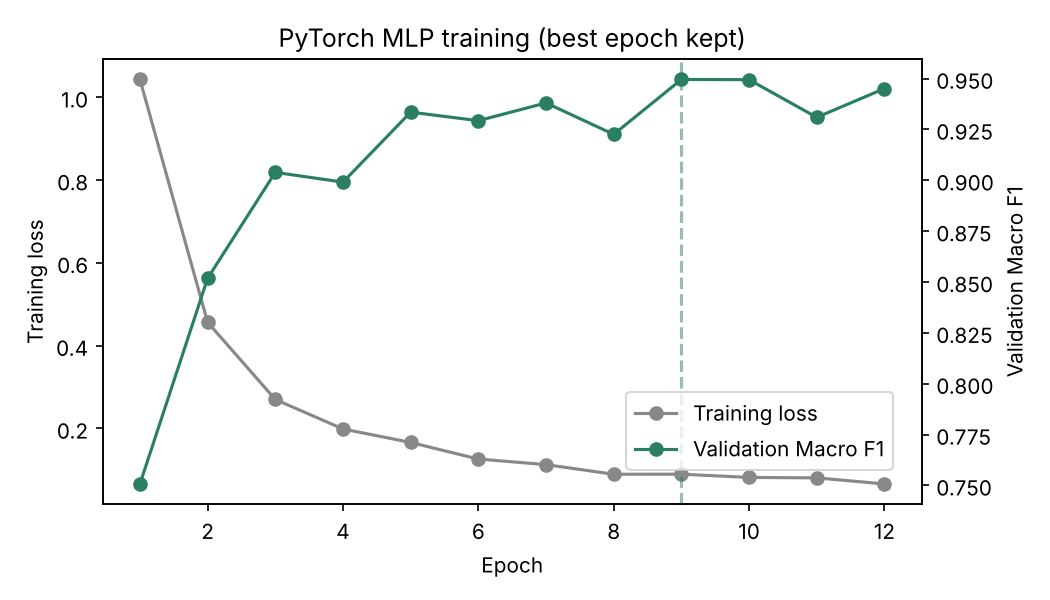

In [5]:
print(f"Validation subjects: {results['mlp']['val_subjects']} | best epoch: {results['mlp']['best_epoch']} "
      f"(validation Macro F1 {results['mlp']['best_val_macro_f1']:.3f})")
display(Image(FIG / "mlp_training.png", width=620))

On the six unseen test subjects the MLP reaches a Macro F1 of **0.937**. It is fast to train
(about 4 s on CPU), but it is 2.9 points below Logistic Regression and also below LightGBM. Because it
receives the same engineered features rather than raw sensor signals, it has little to learn that a linear
model cannot, and the result does not justify the extra complexity of deep learning here.

## Where the best model goes wrong

Logistic Regression has the highest Macro F1, so it gets a closer look.

In [6]:
pd.read_csv(REPORTS / "best_model_class_report.csv", index_col=0).round(3)

,precision,recall,f1-score,support
WALKING,0.994,0.994,0.994,362.000
WALKING_UPSTAIRS,0.962,0.991,0.977,336.000
WALKING_DOWNSTAIRS,1.000,0.958,0.978,308.000
SITTING,0.896,0.953,0.924,407.000
STANDING,0.947,0.910,0.928,431.000
LAYING,1.000,0.986,0.993,442.000
accuracy,0.964,0.964,0.964,0.964
macro avg,0.967,0.965,0.966,2286.000
weighted avg,0.965,0.964,0.964,2286.000


,true,predicted,count
0,STANDING,SITTING,39
1,SITTING,STANDING,19
2,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS,11
3,LAYING,SITTING,6
4,WALKING_UPSTAIRS,STANDING,3


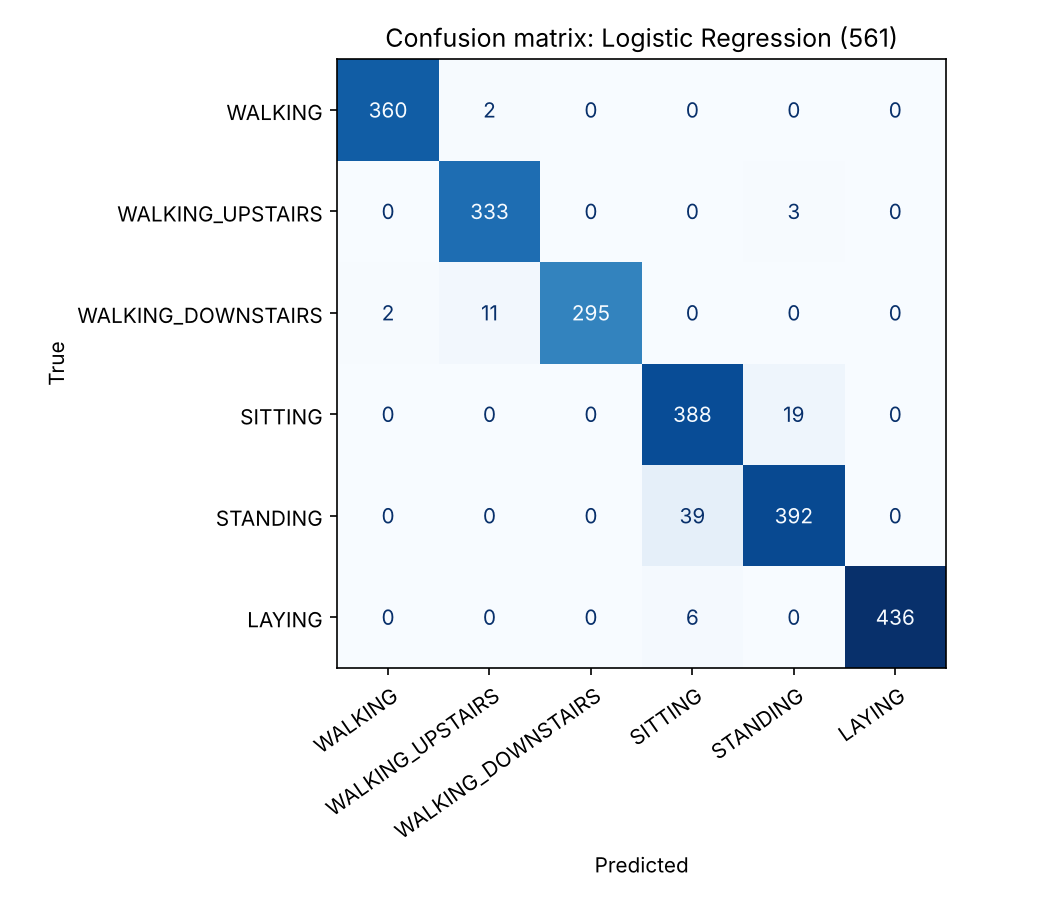

In [7]:
display(pd.read_csv(REPORTS / "best_model_top_confusions.csv"))
display(Image(FIG / "confusion_matrix.png", width=560))

- Logistic Regression ranks first on both Macro F1 (**0.966**) and accuracy; with nearly balanced
  classes the two rankings agree.
- Walking (F1 0.994), laying (0.993) and both stair activities (0.977–0.978) are recognised very reliably.
- Most errors come from the two static postures: **39** standing windows predicted as sitting and **19**
  the other way round, giving the lowest F1 scores (sitting 0.924, standing 0.928). From a waist-worn phone
  the two postures look alike: the body is upright and still in both. A smaller confusion is downstairs vs.
  upstairs (11 windows).
- The gap to the next models is 2–3 points, measured on only six people. Predictive quality alone is not
  enough to choose a model for the device.

Next: [03 · Edge benchmark and recommendation](03_edge_benchmark.ipynb).